# 02 — Full pipeline (self-contained / Colab-ready)

This notebook does **not** import `src`. The first code cell writes the whole
implementation to a local `epn_core.py`, then the notebook imports that. You can
run it on Colab or anywhere else with `torch`, `numpy`, `matplotlib`,
`librosa`/`torchaudio` installed.

It covers: data tensors → CRNN → RED → OOL/IoU losses → short training →
PSDS1/PSDS2/collar-F1 → EPN vs median-filter event extraction.

For the real URBAN-SED run, point `DATA_ROOT` at
`data/processed/urbansed` (see the markdown cell below); otherwise the notebook
builds a tiny synthetic SED dataset so it always executes.

## 0. Implementation

The cell below is the complete core: config, events, RED, EPN, CRNN, losses,
post-processing, metrics and dataset loading. It is a compact copy of the repo
implementation; the repo version remains the source of truth.

**Core 1/7 — frontend config and event rasterisation**


In [1]:
%%writefile epn_core.py
"""Architecture config for the boundary-aware SED model.

This is the ARCHITECTURE-ONLY config (frontend, CRNN widths, RED/EPN switches).
Training-loop hyperparameters (epochs, lr, data paths, loss weights, callback
wiring) live in the training config, so a checkpoint can
rebuild the network without the training YAML.

The model follows "Sound Event Detection with Boundary-Aware Optimization and
Inference" (arXiv:2601.04178):

    log-mel -> CRNN -> 2 logits/class (start, end)
                       -> RED layer -> presence / onset / offset probabilities
                       -> EPN       -> time-since-onset & time-to-offset

Set `use_red=False` for the plain frame-wise BCE baseline, and `use_epn=False`
for the +RED / +OOL ablations.
"""

from dataclasses import dataclass
from typing import Tuple

EPN_VARIANTS = ("per_class", "single")


@dataclass
class SEDConfig:
    """CRNN acoustic model + RED + EPN.

    `num_classes` is filled in at runtime from the dataset. The frontend fields
    must match the values used by `scripts/data/prepare_urbansed.py`; they are
    stored in the processed dataset's `meta.json`.
    """

    # --- task ---
    num_classes: int = 0

    # --- log-mel frontend (must match the precomputed features) ---
    sample_rate: int = 16000
    n_fft: int = 1024
    win_length: int = 400  # 25 ms at 16 kHz
    hop_length: int = 320  # 20 ms -> 50 frames/s
    n_mels: int = 64
    f_min: float = 0.0
    f_max: float = 8000.0
    num_frames: int = 500  # 10 s clips

    # --- CRNN backbone ---
    cnn_channels: Tuple[int, ...] = (16, 32, 64, 128)
    rnn_hidden: int = 128
    rnn_layers: int = 2
    dropout: float = 0.3

    # --- RED / EPN ---
    use_red: bool = True
    use_epn: bool = True
    epn_variant: str = "per_class"
    epn_hidden: int = 32
    epn_layers: int = 2

    def __post_init__(self) -> None:
        if self.num_classes < 0:
            raise ValueError(f"num_classes must be >= 0, got {self.num_classes}")
        if self.sample_rate <= 0 or self.hop_length <= 0:
            raise ValueError("sample_rate and hop_length must be > 0")
        if self.num_frames <= 0:
            raise ValueError(f"num_frames must be > 0, got {self.num_frames}")
        if self.n_mels <= 0:
            raise ValueError(f"n_mels must be > 0, got {self.n_mels}")
        if not self.cnn_channels or any(c <= 0 for c in self.cnn_channels):
            raise ValueError("cnn_channels must be a non-empty tuple of positive ints")
        if self.rnn_hidden <= 0 or self.rnn_layers <= 0:
            raise ValueError("rnn_hidden and rnn_layers must be > 0")
        if not 0.0 <= self.dropout < 1.0:
            raise ValueError(f"dropout must be in [0, 1), got {self.dropout}")
        if self.epn_variant not in EPN_VARIANTS:
            raise ValueError(
                f"unknown epn_variant {self.epn_variant!r}; choose from {EPN_VARIANTS}"
            )
        if self.epn_hidden <= 0 or self.epn_layers <= 0:
            raise ValueError("epn_hidden and epn_layers must be > 0")
        if self.use_epn and not self.use_red:
            raise ValueError("EPN consumes RED outputs; use_epn requires use_red=True")

    @property
    def frame_rate(self) -> float:
        """Frames per second of the model output."""
        return self.sample_rate / self.hop_length

"""Event representation and geometric helpers shared by losses, inference and metrics.

A sound event is `(class_id, onset, offset, score)` in seconds. The same
dataclass is used for ground truth (score ignored / set to 1.0), EPN proposals,
and final predictions. Keeping it tiny and dependency-free lets the
post-processing, inference and evaluation code agree on one representation.
"""

from dataclasses import dataclass
from typing import Iterable, List, Sequence, Tuple


@dataclass(frozen=True)
class Event:
    """A temporal sound event in seconds.

    Attributes:
        class_id: Integer class index.
        onset: Event start time in seconds.
        offset: Event end time in seconds.
        score: Confidence in `[0, 1]`; ground truth uses 1.0.
    """

    class_id: int
    onset: float
    offset: float
    score: float = 1.0

    @property
    def duration(self) -> float:
        """Return the non-negative event duration in seconds.

        Returns:
            `max(offset - onset, 0.0)`.
        """
        return max(self.offset - self.onset, 0.0)

    def clipped(self, start: float, end: float) -> "Event":
        """Clip the event to the interval `[start, end]`.

        Args:
            start: Lower time bound in seconds.
            end: Upper time bound in seconds.

        Returns:
            A new `Event` whose onset/offset lie inside the bounds.
        """
        return Event(
            self.class_id,
            min(max(self.onset, start), end),
            min(max(self.offset, start), end),
            self.score,
        )


def intersection(a: Event, b: Event) -> float:
    """Compute the temporal intersection length of two events.

    Args:
        a: First event.
        b: Second event.

    Returns:
        Overlap in seconds, or 0.0 when the events do not overlap.
    """
    return max(0.0, min(a.offset, b.offset) - max(a.onset, b.onset))


def union(a: Event, b: Event) -> float:
    """Compute the temporal union length of two events.

    Args:
        a: First event.
        b: Second event.

    Returns:
        Union length in seconds.
    """
    return a.duration + b.duration - intersection(a, b)


def iou(a: Event, b: Event) -> float:
    """Compute temporal intersection-over-union.

    Args:
        a: First event.
        b: Second event.

    Returns:
        IoU in `[0, 1]`; 0.0 when either event has zero duration.
    """
    inter = intersection(a, b)
    if inter <= 0.0:
        return 0.0
    denom = a.duration + b.duration - inter
    return inter / denom if denom > 0 else 0.0


def overlaps(a: Event, b: Event) -> bool:
    """Return whether two events share any positive-length interval.

    Args:
        a: First event.
        b: Second event.

    Returns:
        True when `intersection(a, b) > 0`.
    """
    return intersection(a, b) > 0.0


def merge_events(events: Iterable[Event]) -> List[Event]:
    """Merge overlapping or abutting events of the same class.

    URBAN-SED is generated so that a source class does not overlap itself, but
    real annotations can. Merging keeps the frame-level presence label
    well-defined (one region per class) while the original onsets/offsets are
    only used through those merged boundaries.

    Args:
        events: Iterable of possibly overlapping events.

    Returns:
        Events sorted by `(onset, class_id)`, with same-class overlaps merged.
    """
    by_class: dict[int, List[Event]] = {}
    for ev in events:
        if ev.offset <= ev.onset:
            continue
        by_class.setdefault(ev.class_id, []).append(ev)

    merged: List[Event] = []
    for class_id, group in by_class.items():
        group.sort(key=lambda e: e.onset)
        cur = group[0]
        for ev in group[1:]:
            if ev.onset <= cur.offset:
                cur = Event(
                    class_id,
                    cur.onset,
                    max(cur.offset, ev.offset),
                    max(cur.score, ev.score),
                )
            else:
                merged.append(cur)
                cur = ev
        merged.append(cur)
    merged.sort(key=lambda e: (e.onset, e.class_id))
    return merged


def events_to_frames(
    events: Sequence[Event],
    num_classes: int,
    num_frames: int,
    frame_rate: float,
) -> Tuple[List[List[float]], List[List[float]], List[List[float]]]:
    """Rasterise events into per-class presence / onset / offset frame labels.

    A frame covers `[t / frame_rate, (t + 1) / frame_rate)`; an event is active
    on every frame it overlaps. Onsets/offsets are placed on the first active
    frame and the first inactive frame after the event (or the last frame when
    the event hits the right clip boundary).

    Args:
        events: Strong annotations to rasterise.
        num_classes: Number of classes `C`.
        num_frames: Number of frames `T`.
        frame_rate: Frames per second.

    Returns:
        A tuple of three `C x T` nested lists: presence, onset and offset.
    """
    pres = [[0.0] * num_frames for _ in range(num_classes)]
    onset = [[0.0] * num_frames for _ in range(num_classes)]
    offset = [[0.0] * num_frames for _ in range(num_classes)]

    for ev in merge_events(events):
        if not 0 <= ev.class_id < num_classes:
            continue
        start = int(round(ev.onset * frame_rate))
        end = int(round(ev.offset * frame_rate))
        start = min(max(start, 0), num_frames - 1)
        end = min(max(end, start + 1), num_frames)
        onset[ev.class_id][start] = 1.0
        offset[ev.class_id][min(end, num_frames - 1)] = 1.0
        for t in range(start, end):
            pres[ev.class_id][t] = 1.0
    return pres, onset, offset


def frames_to_events(
    presence: Sequence[Sequence[float]],
    frame_rate: float,
    threshold: float = 0.5,
    min_duration: float = 0.0,
) -> List[Event]:
    """Recover events from a `C x T` presence array.

    Used to build ground-truth events at evaluation time (from the frame
    labels) without keeping a second, ragged copy of the annotations around.

    Args:
        presence: Per-class presence values, `C x T`.
        frame_rate: Frames per second.
        threshold: A frame is active when `value >= threshold`.
        min_duration: Drop shorter events (seconds).

    Returns:
        Events sorted by class and time.
    """
    events: List[Event] = []
    for class_id, row in enumerate(presence):
        active = False
        start = 0
        for t, value in enumerate(row):
            on = value >= threshold
            if on and not active:
                active, start = True, t
            elif not on and active:
                active = False
                onset_s, offset_s = start / frame_rate, t / frame_rate
                if offset_s - onset_s >= min_duration:
                    events.append(Event(class_id, onset_s, offset_s, 1.0))
        if active:
            onset_s, offset_s = start / frame_rate, len(row) / frame_rate
            if offset_s - onset_s >= min_duration:
                events.append(Event(class_id, onset_s, offset_s, 1.0))
    return events



Writing epn_core.py


**Core 2/7 — RED layer and its parallel scan**


In [2]:
%%writefile -a epn_core.py
"""Recurrent Event Detection (RED) layer.

RED (arXiv:2601.04178, Sec. II-A) turns two conditional boundary probabilities
into frame-wise event presence, onset and offset probabilities with a
parameter-free probabilistic recurrence. Omitting the class index:

    p_t       = p_start_t * (1 - p_{t-1}) + (1 - p_end_t) * p_{t-1}
    onset_t   = p_start_t * (1 - p_{t-1})
    offset_t  = p_end_t   * p_{t-1}
    p_{-1}    = 0

where `p_start_t = P(e_t | not e_{t-1})`, `p_end_t = P(not e_t | e_{t-1})`,
and `p_t = P(e_t)` is event presence.

The recurrence is a first-order linear scan `p_t = a_t p_{t-1} + b_t` with
`a_t = 1 - p_start_t - p_end_t` and `b_t = p_start_t`. It is evaluated with a
Hillis-Steele parallel prefix scan (the same associative composition as
Heinsen's scan [arXiv:2311.06281]), so the Python loop is over `log2(T)` steps
instead of `T`. A sequential reference implementation is kept for testing.
"""

from typing import Optional

import torch
import torch.nn as nn


def _scan_compose(
    a_left: torch.Tensor,
    b_left: torch.Tensor,
    a_right: torch.Tensor,
    b_right: torch.Tensor,
) -> tuple[torch.Tensor, torch.Tensor]:
    """Compose two affine recurrences applied left then right.

    Args:
        a_left: Multipliers of the left recurrence.
        b_left: Offsets of the left recurrence.
        a_right: Multipliers of the right recurrence.
        b_right: Offsets of the right recurrence.

    Returns:
        The composed `(a, b)` with `a = a_right * a_left` and
        `b = a_right * b_left + b_right`.
    """
    return a_right * a_left, a_right * b_left + b_right


def parallel_scan(
    a: torch.Tensor, b: torch.Tensor
) -> tuple[torch.Tensor, torch.Tensor]:
    """Inclusive prefix scan of `x_t = a_t * x_{t-1} + b_t` along the last dim.

    `a` and `b` are `(..., T)` and the initial state is zero. Returns
    `(A, B)` such that `x_t = A_t * x_{-1} + B_t`; with `x_{-1}=0`, `x_t = B_t`.
    The scan is exact in exact arithmetic and uses `log2(T)` vectorised steps.

    Args:
        a: Recurrence multipliers, `(..., T)`.
        b: Recurrence offsets, `(..., T)`.

    Returns:
        `(A, B)`, both `(..., T)`, the inclusive scan coefficients.

    Raises:
        ValueError: If `a` and `b` do not have the same shape.
    """
    if a.shape != b.shape:
        raise ValueError(f"a and b must have the same shape, got {a.shape} vs {b.shape}")
    t = a.shape[-1]
    aa, bb = a, b
    step = 1
    while step < t:
        a_prev = torch.ones_like(aa)
        b_prev = torch.zeros_like(bb)
        a_prev[..., step:] = aa[..., :-step]
        b_prev[..., step:] = bb[..., :-step]
        aa, bb = _scan_compose(a_prev, b_prev, aa, bb)
        step *= 2
    return aa, bb


def sequential_red(
    p_start: torch.Tensor, p_end: torch.Tensor
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """Evaluate RED one frame at a time as a reference implementation.

    Args:
        p_start: Conditional start probabilities, `(B, C, T)`.
        p_end: Conditional end probabilities, `(B, C, T)`.

    Returns:
        `(presence, onset, offset)` probabilities, each `(B, C, T)`.
    """
    batch, classes, frames = p_start.shape
    pres = []
    prev = torch.zeros(batch, classes, device=p_start.device, dtype=p_start.dtype)
    for t in range(frames):
        s, e = p_start[..., t], p_end[..., t]
        cur = s * (1.0 - prev) + (1.0 - e) * prev
        pres.append(cur)
        prev = cur
    pres_t = torch.stack(pres, dim=-1)
    prev = torch.cat(
        [
            torch.zeros(batch, classes, 1, device=p_start.device, dtype=p_start.dtype),
            pres_t[..., :-1],
        ],
        dim=-1,
    )
    onset = p_start * (1.0 - prev)
    offset = p_end * prev
    return pres_t, onset, offset


class RED(nn.Module):
    """Parameter-free, differentiable RED layer.

    `forward` accepts start/end logits (the acoustic model's raw outputs) and an
    optional boolean `mask` of shape `(B, T)` where `False` marks padded frames.
    Padded frames carry the previous state but their outputs are zeroed, so a
    padded tail cannot create spurious events.
    """

    def __init__(self, eps: float = 1e-6) -> None:
        """Initialise the RED layer.

        Args:
            eps: Clamp bound applied to presence probabilities before they are
                used as the previous-frame state.
        """
        super().__init__()
        self.eps = eps

    def forward(
        self,
        start_logits: torch.Tensor,
        end_logits: torch.Tensor,
        mask: Optional[torch.Tensor] = None,
    ) -> dict[str, torch.Tensor]:
        """Convert start/end logits into boundary-aware probabilities.

        Padded frames carry the previous state but their outputs are zeroed, so
        a padded tail cannot create spurious events.

        Args:
            start_logits: Acoustic model start logits, `(B, C, T)`.
            end_logits: Acoustic model end logits, `(B, C, T)`.
            mask: Optional boolean `(B, T)`; `False` marks padded frames.

        Returns:
            A dict with `presence`, `onset`, `offset`, `p_start` and `p_end`,
            each `(B, C, T)`.

        Raises:
            ValueError: If the start and end tensors have different shapes.
        """
        if start_logits.shape != end_logits.shape:
            raise ValueError(
                "start/end logits must match: "
                f"{tuple(start_logits.shape)} vs {tuple(end_logits.shape)}"
            )
        p_start = torch.sigmoid(start_logits)
        p_end = torch.sigmoid(end_logits)

        a = 1.0 - p_start - p_end
        b = p_start
        if mask is not None:
            # Carry the state through padded frames; their outputs are masked
            # below. `a=1, b=0` is the identity of the affine scan.
            valid = mask.to(dtype=a.dtype).unsqueeze(1)
            a = torch.where(valid > 0, a, torch.ones_like(a))
            b = torch.where(valid > 0, b, torch.zeros_like(b))

        _, pres = parallel_scan(a, b)
        pres = pres.clamp(self.eps, 1.0 - self.eps)

        prev = torch.cat(
            [
                torch.zeros_like(pres[..., :1]),
                pres[..., :-1],
            ],
            dim=-1,
        )
        onset = (p_start * (1.0 - prev)).clamp(0.0, 1.0)
        offset = (p_end * prev).clamp(0.0, 1.0)

        if mask is not None:
            valid = mask.unsqueeze(1)
            pres = pres * valid
            onset = onset * valid
            offset = offset * valid

        return {
            "presence": pres,
            "onset": onset,
            "offset": offset,
            "p_start": p_start,
            "p_end": p_end,
        }



Appending to epn_core.py


**Core 3/7 — EPN and the CRNN backbone**


In [3]:
%%writefile -a epn_core.py
"""Event Proposal Networks (EPN).

EPN (arXiv:2601.04178, Sec. II-C) predicts two non-negative durations at every
frame: time since the event onset (`d_on`) and time to the event offset
(`d_off`). The interval `[t - d_on, t + d_off]` is a region proposal that is
trained with the duration-weighted IoU loss. Two variants from the paper:

* `per_class`: one bidirectional GRU per class, input `(B, T, 3)`.
* `single`: one bidirectional GRU over all classes, input `(B, T, 3C)`,
  output `(B, T, 2C)`; used for many-class datasets.

The GRUs consume the RED probabilities `[presence, onset, offset]`.
"""

import torch
import torch.nn as nn
import torch.nn.functional as F



class _DurationHead(nn.Module):
    """Bidirectional GRU followed by a linear head with Softplus output."""

    def __init__(self, input_dim: int, hidden: int, layers: int, out_dim: int) -> None:
        """Build one duration head.

        Args:
            input_dim: Number of input channels per frame.
            hidden: GRU hidden size per direction.
            layers: Number of stacked GRU layers.
            out_dim: Number of non-negative outputs per frame.
        """
        super().__init__()
        self.gru = nn.GRU(
            input_dim,
            hidden,
            num_layers=layers,
            batch_first=True,
            bidirectional=True,
            dropout=0.0 if layers == 1 else 0.1,
        )
        self.head = nn.Linear(2 * hidden, out_dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Predict non-negative durations for a sequence.

        Args:
            x: Frame features, `(N, T, input_dim)`.

        Returns:
            `(N, T, out_dim)` values after Softplus.
        """
        # x: (N, T, input_dim) -> (N, T, out_dim), Softplus keeps durations >= 0.
        out, _ = self.gru(x)
        return F.softplus(self.head(out))


class EventProposalNetwork(nn.Module):
    """Per-class or single-GRU duration predictor.

    Inputs are the RED outputs `(B, C, T)`; outputs `don`, `doff` are
    `(B, C, T)` in seconds.
    """

    def __init__(self, cfg: SEDConfig) -> None:
        """Build the EPN variant requested by `cfg.epn_variant`.

        Args:
            cfg: Architecture config; `epn_variant` selects one GRU per class
                or one GRU over all class channels.

        Raises:
            ValueError: If `epn_variant` is not one of `per_class` / `single`.
        """
        super().__init__()
        self.cfg = cfg
        if cfg.epn_variant == "per_class":
            self.heads = nn.ModuleList(
                [
                    _DurationHead(3, cfg.epn_hidden, cfg.epn_layers, 2)
                    for _ in range(cfg.num_classes)
                ]
            )
        elif cfg.epn_variant == "single":
            self.head = _DurationHead(
                3 * cfg.num_classes,
                cfg.epn_hidden,
                cfg.epn_layers,
                2 * cfg.num_classes,
            )
        else:  # guarded by SEDConfig, kept for clarity
            raise ValueError(f"unknown epn_variant: {cfg.epn_variant!r}")

    def forward(
        self,
        presence: torch.Tensor,
        onset: torch.Tensor,
        offset: torch.Tensor,
    ) -> tuple[torch.Tensor, torch.Tensor]:
        """Predict time-since-onset and time-to-offset at every frame.

        Args:
            presence: RED presence probabilities, `(B, C, T)`.
            onset: RED onset probabilities, `(B, C, T)`.
            offset: RED offset probabilities, `(B, C, T)`.

        Returns:
            `(don, doff)`, each `(B, C, T)` in seconds and non-negative.
        """
        # (B, C, T) -> (B, T, C)
        feats = torch.stack([presence, onset, offset], dim=-1).permute(0, 2, 1, 3)
        # feats: (B, T, C, 3)

        if self.cfg.epn_variant == "per_class":
            outs = []
            for c, head in enumerate(self.heads):
                outs.append(head(feats[:, :, c, :]))
            durations = torch.stack(outs, dim=2)  # (B, T, C, 2)
        else:
            flat = feats.reshape(feats.shape[0], feats.shape[1], -1)
            durations = self.head(flat).reshape(
                feats.shape[0], feats.shape[1], self.cfg.num_classes, 2
            )

        durations = durations.permute(0, 2, 1, 3)  # (B, C, T, 2)
        return durations[..., 0], durations[..., 1]

"""Boundary-aware CRNN for sound event detection.

Two model families share one convolutional-recurrent backbone:

* `FrameCRNN` — the paper's frame-wise baseline: one presence logit per class.
* `BoundaryAwareCRNN` — two logits per class (event start / event end), a RED
  layer that converts them into presence/onset/offset probabilities, and an
  optional EPN that predicts onset/offset durations.

`forward` returns a dict so the training loop, evaluator and inference code can
consume RED/EPN outputs without knowing which ablation produced them.
"""

from typing import Optional

import torch
import torch.nn as nn
import torch.nn.functional as F



class ConvBlock(nn.Module):
    """Conv2d -> BatchNorm -> ReLU -> MaxPool(2, 2)."""

    def __init__(self, in_ch: int, out_ch: int, dropout: float = 0.0) -> None:
        """Build one convolutional block.

        Args:
            in_ch: Input feature maps.
            out_ch: Output feature maps.
            dropout: Spatial dropout probability after the activation.
        """
        super().__init__()
        self.conv = nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False)
        self.bn = nn.BatchNorm2d(out_ch)
        self.drop = nn.Dropout2d(dropout) if dropout > 0 else nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Apply conv, batch-norm, ReLU, dropout and 2x2 max-pooling.

        Args:
            x: Feature map, `(B, in_ch, T, F)`.

        Returns:
            Pooled feature map, `(B, out_ch, T // 2, F // 2)`.
        """
        x = F.relu(self.bn(self.conv(x)), inplace=True)
        x = self.drop(x)
        return F.max_pool2d(x, kernel_size=2, stride=2)


class CRNNBackbone(nn.Module):
    """4 conv blocks (time/frequency pooling) followed by a bidirectional GRU.

    Input `(B, 1, T, F)` -> output `(B, T, 2 * rnn_hidden)`. The recurrent output
    is interpolated back to the input frame rate so frame labels align.
    """

    def __init__(self, cfg: SEDConfig) -> None:
        """Build the convolutional and recurrent stack.

        Args:
            cfg: Architecture config with channel widths and GRU size.
        """
        super().__init__()
        self.cfg = cfg
        blocks = []
        in_ch = 1
        for i, out_ch in enumerate(cfg.cnn_channels):
            blocks.append(ConvBlock(in_ch, out_ch, dropout=0.0 if i == 0 else 0.1))
            in_ch = out_ch
        self.convs = nn.Sequential(*blocks)

        # Frequency is halved by every 2x2 pool; the GRU sees the flattened
        # channel x frequency map at each pooled time step.
        reduced_freq = max(cfg.n_mels // (2 ** len(cfg.cnn_channels)), 1)
        self.rnn_input_dim = in_ch * reduced_freq
        self.rnn = nn.GRU(
            self.rnn_input_dim,
            cfg.rnn_hidden,
            num_layers=cfg.rnn_layers,
            batch_first=True,
            bidirectional=True,
            dropout=0.0 if cfg.rnn_layers == 1 else cfg.dropout,
        )
        self.out_dim = 2 * cfg.rnn_hidden
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Encode a log-mel batch at the original frame rate.

        Args:
            x: Log-mel features, `(B, 1, T, F)`.

        Returns:
            Frame features `(B, T, 2 * rnn_hidden)`.

        Raises:
            ValueError: If the input is not 4-D or is too short for four
                pooling stages.
        """
        # x: (B, 1, T, F)
        if x.dim() != 4:
            raise ValueError(f"expected (B, 1, T, F), got {tuple(x.shape)}")
        target_frames = x.shape[2]
        h = self.convs(x)  # (B, C, T', F')
        b, c, t, f = h.shape
        if t < 1 or f < 1:
            raise ValueError(f"input too short for the conv stack: {tuple(x.shape)}")
        h = h.permute(0, 2, 1, 3).reshape(b, t, c * f)
        if c * f != self.rnn_input_dim:
            raise ValueError(
                "input n_mels does not match the configured frontend: "
                f"pooled features have {c * f} channels, expected {self.rnn_input_dim}"
            )
        h, _ = self.rnn(h)
        h = self.drop(h)
        h = h.transpose(1, 2)  # (B, 2H, T')
        h = F.interpolate(h, size=target_frames, mode="linear", align_corners=False)
        return h.transpose(1, 2)  # (B, T, 2H)


class FrameCRNN(nn.Module):
    """Frame-wise baseline: log-mel -> presence logits `(B, C, T)`."""

    def __init__(self, cfg: SEDConfig) -> None:
        """Build the frame-wise baseline.

        Args:
            cfg: Architecture config with `num_classes` set.

        Raises:
            ValueError: If `cfg.num_classes <= 0`.
        """
        super().__init__()
        if cfg.num_classes <= 0:
            raise ValueError("SEDConfig.num_classes must be > 0 before building")
        self.cfg = cfg
        self.backbone = CRNNBackbone(cfg)
        self.head = nn.Linear(self.backbone.out_dim, cfg.num_classes)

    def get_embedding(self, x: torch.Tensor) -> torch.Tensor:
        """Return the penultimate frame features.

        Args:
            x: Log-mel features, `(B, 1, T, F)`.

        Returns:
            Frame features `(B, T, 2 * rnn_hidden)`.
        """
        return self.backbone(x)

    def forward(
        self, x: torch.Tensor, lengths: Optional[torch.Tensor] = None
    ) -> dict[str, torch.Tensor]:
        """Predict per-class presence logits.

        Args:
            x: Log-mel features, `(B, 1, T, F)`.
            lengths: Optional valid lengths `(B,)`; accepted for interface
                parity with the RED model.

        Returns:
            A dict with `pres_logits` `(B, C, T)` and `feature` `(B, T, H)`.
        """
        feat = self.backbone(x)
        logits = self.head(feat).transpose(1, 2)  # (B, C, T)
        return {"pres_logits": logits, "feature": feat}


class BoundaryAwareCRNN(nn.Module):
    """CRNN + RED (+ optional EPN) from arXiv:2601.04178."""

    def __init__(self, cfg: SEDConfig) -> None:
        """Build the RED/EPN model.

        Args:
            cfg: Architecture config with `num_classes` set and optional
                `use_red` / `use_epn` ablations.

        Raises:
            ValueError: If `cfg.num_classes <= 0`.
        """
        super().__init__()
        if cfg.num_classes <= 0:
            raise ValueError("SEDConfig.num_classes must be > 0 before building")
        self.cfg = cfg
        self.backbone = CRNNBackbone(cfg)
        self.head = nn.Linear(self.backbone.out_dim, 2 * cfg.num_classes)
        self.red = RED()
        self.epn = EventProposalNetwork(cfg) if cfg.use_epn else None

    def get_embedding(self, x: torch.Tensor) -> torch.Tensor:
        """Return the penultimate frame features.

        Args:
            x: Log-mel features, `(B, 1, T, F)`.

        Returns:
            Frame features `(B, T, 2 * rnn_hidden)`.
        """
        return self.backbone(x)

    def forward(
        self, x: torch.Tensor, lengths: Optional[torch.Tensor] = None
    ) -> dict[str, torch.Tensor]:
        """Predict boundaries, presence and (optionally) event durations.

        Args:
            x: Log-mel features, `(B, 1, T, F)`.
            lengths: Optional valid lengths `(B,)`; padded frames are masked.

        Returns:
            A dict with `start_logits` / `end_logits` / `presence` / `onset` /
            `offset` / `feature`, plus `don` / `doff` when EPN is enabled.
        """
        feat = self.backbone(x)
        b, t, _ = feat.shape
        c = self.cfg.num_classes
        se = self.head(feat).reshape(b, t, c, 2).permute(0, 2, 3, 1)
        start_logits, end_logits = se[:, :, 0, :], se[:, :, 1, :]  # (B, C, T)

        mask = None
        if lengths is not None:
            mask = torch.arange(t, device=x.device).unsqueeze(0) < lengths.unsqueeze(1)

        red = self.red(start_logits, end_logits, mask=mask)
        out = {
            "start_logits": start_logits,
            "end_logits": end_logits,
            "presence": red["presence"],
            "onset": red["onset"],
            "offset": red["offset"],
            "feature": feat,
        }
        if self.epn is not None:
            don, doff = self.epn(red["presence"], red["onset"], red["offset"])
            out["don"] = don
            out["doff"] = doff
        return out


def build_model(cfg: SEDConfig) -> nn.Module:
    """Build the model family selected by `cfg.use_red`.

    Args:
        cfg: Architecture config with `num_classes` set.

    Returns:
        `BoundaryAwareCRNN` when `use_red` is true, else `FrameCRNN`.
    """
    return BoundaryAwareCRNN(cfg) if cfg.use_red else FrameCRNN(cfg)


def presence_probability(outputs: dict[str, torch.Tensor]) -> torch.Tensor:
    """Read presence probabilities from either model family.

    Args:
        outputs: A model output dict.

    Returns:
        Presence probabilities, `(B, C, T)`.

    Raises:
        KeyError: If the dict has neither `presence` nor `pres_logits`.
    """
    if "presence" in outputs:
        return outputs["presence"]
    if "pres_logits" in outputs:
        return torch.sigmoid(outputs["pres_logits"])
    raise KeyError("model output has neither 'presence' nor 'pres_logits'")



Appending to epn_core.py


**Core 4/7 — presence BCE, focal OOL and duration-weighted IoU**


In [4]:
%%writefile -a epn_core.py
"""Boundary-aware SED losses (arXiv:2601.04178, Sec. II-B/II-C).

    L_total = L_pres + lambda_ool * (L_on + L_off) + lambda_iou * L_iou

* `L_pres`  — frame-wise binary cross-entropy on RED presence probabilities
              (or on the frame-wise baseline's sigmoid logits).
* `L_on/off` — focal loss (alpha=2) on the impulse-like onset/offset labels.
* `L_iou`   — duration-weighted IoU loss between the ground-truth interval
              `[t - d_on, t + d_off]` and the EPN proposal, on active frames.

The IoU loss is computed in closed form because both intervals contain `t`:
`IoU = (min(don, don_hat) + min(doff, doff_hat)) / (max(...) + max(...))`.
"""

from typing import Optional

import torch
import torch.nn as nn
import torch.nn.functional as F


EPS = 1e-7


def focal_loss(
    probs: torch.Tensor,
    targets: torch.Tensor,
    alpha: float = 2.0,
    mask: Optional[torch.Tensor] = None,
) -> torch.Tensor:
    """Binary focal loss, averaged over valid elements.

    `probs`/`targets` are `(..., T)`; `mask` broadcasts over the leading dims.
    """
    probs = probs.clamp(EPS, 1.0 - EPS)
    pos = (1.0 - probs).pow(alpha) * probs.log()
    neg = probs.pow(alpha) * torch.log1p(-probs)
    loss = -(targets * pos + (1.0 - targets) * neg)
    if mask is not None:
        loss = loss * mask
        return loss.sum() / mask.sum().clamp(min=1.0)
    return loss.mean()


def iou_loss(
    don: torch.Tensor,
    doff: torch.Tensor,
    don_gt: torch.Tensor,
    doff_gt: torch.Tensor,
    active: torch.Tensor,
) -> torch.Tensor:
    """Duration-weighted IoU loss on active frames (Eq. 4).

    All inputs are `(B, C, T)`. `active` is the ground-truth presence mask.
    """
    inter = torch.minimum(don, don_gt) + torch.minimum(doff, doff_gt)
    union = torch.maximum(don, don_gt) + torch.maximum(doff, doff_gt)
    iou = inter / union.clamp(min=EPS)
    weight = don_gt + doff_gt
    per_frame = (1.0 - iou) * weight
    denom = active.sum().clamp(min=1.0)
    return (per_frame * active).sum() / denom


class SEDLoss(nn.Module):
    """Combined presence + onset/offset + IoU objective.

    `use_ool` / `use_epn` follow the architecture switches; the ablation
    `BL -> +RED -> +OOL -> +EPN` is exactly:
        use_red=False
        use_red=True,  use_ool=False, use_epn=False
        use_red=True,  use_ool=True,  use_epn=False
        use_red=True,  use_ool=True,  use_epn=True
    """

    def __init__(
        self,
        cfg: SEDConfig,
        lambda_ool: float = 100.0,
        lambda_iou: float = 2.0,
        focal_alpha: float = 2.0,
        use_ool: Optional[bool] = None,
        use_epn: Optional[bool] = None,
    ) -> None:
        """Configure the combined objective.

        Args:
            cfg: Architecture config; supplies the `use_red` / `use_epn`
                defaults for the ablation switches.
            lambda_ool: Weight on the summed onset + offset focal losses.
            lambda_iou: Weight on the duration-weighted IoU loss.
            focal_alpha: Focusing parameter for the boundary focal loss.
            use_ool: Override for the onset/offset loss switch.
            use_epn: Override for the IoU loss switch.

        Raises:
            ValueError: If the IoU loss is enabled without a RED model.
        """
        super().__init__()
        self.cfg = cfg
        self.lambda_ool = float(lambda_ool)
        self.lambda_iou = float(lambda_iou)
        self.focal_alpha = float(focal_alpha)
        self.use_ool = cfg.use_red if use_ool is None else bool(use_ool)
        self.use_epn = cfg.use_epn if use_epn is None else bool(use_epn)
        if self.use_epn and not cfg.use_red:
            raise ValueError("IoU loss needs EPN outputs, which need RED")

    def forward(
        self,
        outputs: dict[str, torch.Tensor],
        batch: dict[str, torch.Tensor],
        mask: Optional[torch.Tensor] = None,
    ) -> dict[str, torch.Tensor]:
        """Compute every loss component and their weighted sum.

        Args:
            outputs: Model output dict.
            batch: Target dict with `pres`, `on`, `off`, `don`, `doff`, each
                `(B, C, T)`.
            mask: Optional boolean `(B, T)` valid-frame mask.

        Returns:
            A dict with scalar tensors `loss`, `pres`, `ool` and `iou`.
        """
        pres = presence_probability(outputs).clamp(EPS, 1.0 - EPS)
        y_pres = batch["pres"].float()
        if mask is None:
            mask_frames = torch.ones_like(y_pres)
        else:
            mask_frames = mask.unsqueeze(1).to(y_pres.dtype)

        if mask is None:
            loss_pres = F.binary_cross_entropy(pres, y_pres)
        else:
            bce = F.binary_cross_entropy(pres, y_pres, reduction="none")
            loss_pres = (bce * mask_frames).sum() / mask_frames.sum().clamp(min=1.0)

        zero = pres.new_zeros(())
        loss_ool = zero
        if self.use_ool:
            if "onset" not in outputs or "offset" not in outputs:
                raise KeyError("use_ool=True requires a RED model")
            focal_mask = None if mask is None else mask.unsqueeze(1)
            loss_on = focal_loss(
                outputs["onset"], batch["on"].float(), self.focal_alpha, focal_mask
            )
            loss_off = focal_loss(
                outputs["offset"], batch["off"].float(), self.focal_alpha, focal_mask
            )
            loss_ool = loss_on + loss_off

        loss_iou = zero
        if self.use_epn:
            if "don" not in outputs or "doff" not in outputs:
                raise KeyError("EPN loss requires EPN outputs")
            loss_iou = iou_loss(
                outputs["don"],
                outputs["doff"],
                batch["don"].float(),
                batch["doff"].float(),
                y_pres * mask_frames,
            )

        total = loss_pres + self.lambda_ool * loss_ool + self.lambda_iou * loss_iou
        return {
            "loss": total,
            "pres": loss_pres,
            "ool": loss_ool,
            "iou": loss_iou,
        }



Appending to epn_core.py


**Core 5/7 — median filtering and Algorithm 1 inference**


In [5]:
%%writefile -a epn_core.py
"""Post-processing and event inference.

Two ways to turn frame-wise probabilities into events:

1. `median_filter_events` — the standard frame-wise baseline: median filter
   presence probabilities, threshold, group consecutive active frames.
2. `epn_inference` — Algorithm 1 from arXiv:2601.04178: sort proposals by RED
   presence, emit `[t - d_on, t + d_off]`, and suppress overlapping proposals
   (non-maximum-suppression-like), keeping at most `k` events per class and
   considering only the `m` most active classes.

Both return `list[list[Event]]` (one list per clip) so the evaluator can consume
them uniformly.
"""

from typing import List, Optional

import numpy as np
import torch
import torch.nn.functional as F



def median_filter_probs(probs: torch.Tensor, kernel_size: int) -> torch.Tensor:
    """Median filter `(B, C, T)` probabilities along time (replicate padding)."""
    if kernel_size <= 1:
        return probs
    if kernel_size % 2 == 0:
        raise ValueError(f"median filter length must be odd, got {kernel_size}")
    pad = kernel_size // 2
    x = F.pad(probs, (pad, pad), mode="replicate")
    windows = x.unfold(-1, kernel_size, 1)
    return windows.median(dim=-1).values


def _runs(mask: np.ndarray) -> List[tuple[int, int]]:
    """Find half-open runs of True in a 1-D boolean array.

    Args:
        mask: Boolean activity mask.

    Returns:
        A list of `(start, end)` pairs with `end` exclusive.
    """
    padded = np.concatenate([[False], mask, [False]])
    changes = np.flatnonzero(padded[1:] != padded[:-1])
    return [(int(changes[i]), int(changes[i + 1])) for i in range(0, len(changes), 2)]


def median_filter_events(
    presence: torch.Tensor,
    frame_rate: float,
    threshold: float = 0.5,
    filter_len: int = 7,
    min_duration: float = 0.0,
) -> List[List[Event]]:
    """Extract events from presence probabilities via median filtering.

    Args:
        presence: Presence probabilities, `(B, C, T)`.
        frame_rate: Frames per second.
        threshold: Activity threshold applied after filtering.
        filter_len: Odd median-filter length in frames.
        min_duration: Drop shorter events (seconds).

    Returns:
        One event list per clip.

    Raises:
        ValueError: If `presence` is not 3-D.
    """
    if presence.dim() != 3:
        raise ValueError(f"expected (B, C, T), got {tuple(presence.shape)}")
    filtered = median_filter_probs(presence.detach().float().cpu(), filter_len)
    active = (filtered >= threshold).numpy()
    out: List[List[Event]] = []
    for b in range(active.shape[0]):
        events: List[Event] = []
        for c in range(active.shape[1]):
            for start, end in _runs(active[b, c]):
                onset, offset = start / frame_rate, end / frame_rate
                if offset - onset < min_duration or end <= start:
                    continue
                score = float(filtered[b, c, start:end].mean().item())
                events.append(Event(c, onset, offset, score))
        out.append(events)
    return out


def epn_inference(
    presence: torch.Tensor,
    don: torch.Tensor,
    doff: torch.Tensor,
    frame_rate: float,
    clip_duration: float,
    k: int = 15,
    m: Optional[int] = None,
    min_score: float = 1e-3,
    min_duration: float = 0.0,
) -> List[List[Event]]:
    """Algorithm 1 (event inference) for `(B, C, T)` RED/EPN outputs.

    Args:
        presence: RED presence probabilities, `(B, C, T)`.
        don, doff: EPN durations in seconds, `(B, C, T)`.
        k: maximum events per class.
        m: number of most-active classes to consider; `None` means all.
        min_score: ignore proposal frames below this presence probability.
        min_duration: drop proposals shorter than this (seconds).

    Returns:
        One event list per clip, sorted by onset then class.

    Raises:
        ValueError: If the three tensors do not share the same shape.
    """
    if presence.shape != don.shape or presence.shape != doff.shape:
        raise ValueError("presence/don/doff must have the same (B, C, T) shape")
    pres = presence.detach().float().cpu().numpy()
    don_np = don.detach().float().cpu().numpy()
    doff_np = doff.detach().float().cpu().numpy()

    batch, classes, frames = pres.shape
    m = classes if m is None else max(1, min(int(m), classes))
    out: List[List[Event]] = []

    for b in range(batch):
        class_scores = pres[b].mean(axis=1)
        selected_classes = np.argsort(-class_scores)[:m]
        events: List[Event] = []

        for c in selected_classes:
            cand = np.flatnonzero(pres[b, c] > min_score)
            if cand.size == 0:
                continue
            cand = cand[np.argsort(-pres[b, c, cand])]
            removed = np.zeros(frames, dtype=bool)
            n_class_events = 0

            for t in cand:
                if n_class_events >= k:
                    break
                if removed[t]:
                    continue
                left = t / frame_rate - don_np[b, c, t]
                right = t / frame_rate + doff_np[b, c, t]
                left = float(np.clip(left, 0.0, clip_duration))
                right = float(np.clip(right, 0.0, clip_duration))
                if right - left < min_duration or right <= left:
                    removed[t] = True
                    continue

                # Suppress every proposal that overlaps the chosen interval.
                cand_left = cand / frame_rate - don_np[b, c, cand]
                cand_right = cand / frame_rate + doff_np[b, c, cand]
                overlapping = (cand_left < right) & (cand_right > left)
                removed[cand[overlapping]] = True

                f0 = max(int(np.floor(left * frame_rate)), 0)
                f1 = min(int(np.ceil(right * frame_rate)), frames)
                score = float(pres[b, c, f0:f1].mean()) if f1 > f0 else 0.0
                events.append(Event(int(c), left, right, score))
                n_class_events += 1

        events.sort(key=lambda e: (e.onset, e.class_id))
        out.append(events)
    return out


def events_from_model_output(
    outputs: dict[str, torch.Tensor],
    cfg: SEDConfig,
    method: str = "epn",
    threshold: float = 0.5,
    filter_len: int = 7,
    k: int = 15,
    m: Optional[int] = None,
    min_duration: float = 0.0,
) -> List[List[Event]]:
    """Dispatch RED/EPN outputs to the requested event extractor."""

    presence = presence_probability(outputs)
    if method == "epn":
        if "don" not in outputs:
            raise KeyError("method='epn' requires EPN outputs (don/doff)")
        return epn_inference(
            presence,
            outputs["don"],
            outputs["doff"],
            frame_rate=cfg.frame_rate,
            clip_duration=cfg.num_frames / cfg.frame_rate,
            k=k,
            m=m,
            min_duration=min_duration,
        )
    if method == "median":
        return median_filter_events(
            presence,
            frame_rate=cfg.frame_rate,
            threshold=threshold,
            filter_len=filter_len,
            min_duration=min_duration,
        )
    raise ValueError(f"unknown event extraction method: {method!r}")



Appending to epn_core.py


**Core 6/7 — PSDS1, PSDS2 and collar-F1**


In [6]:
%%writefile -a epn_core.py
"""Event-based SED metrics: PSDS1 and collar-based F1.

Both metrics operate on `list[list[Event]]` (one list per clip), so the same
functions evaluate EPN inference and the median-filter baseline.

PSDS1 (arXiv:2601.04178, Sec. III-A) follows the DCASE definition: for a grid
of operating points (one global score threshold per point), count per-class
true positives with an IoU-0.5 matching criterion, build the TPR vs effective
false-positive-rate curve, average TPR over classes, and integrate. We omit the
cross-trigger term and the inter-class variance penalty (`alpha_ct=0`,
`alpha_st=0`), which is exactly the paper's "PSDS1 without variance penalty".

PSDS2 is the DCASE scenario-2 metric: DTC/GTC 0.1, CTTC 0.3, cross-trigger
weight 0.5 and inter-class variance penalty 1.0. It is reported alongside PSDS1
because it emphasises class recognition rather than boundary precision.

Collar F1 matches events with a 200 ms onset collar and an offset collar of
`max(200 ms, 20% of the ground-truth duration)`, then pools TP/FP/FN.
"""

from typing import Dict, Iterable, List, Optional, Sequence

import numpy as np


Counts = Dict[int, Dict[str, int]]


def _empty_counts() -> Counts:
    """Return an empty per-class count table.

    Returns:
        An empty dict.
    """
    return {}


def _bump(counts: Counts, class_id: int, key: str, amount: int = 1) -> None:
    """Increment one TP/FP/FN counter for a class.

    Args:
        counts: Mutable per-class count table.
        class_id: Event class index.
        key: One of `tp`, `fp`, `fn`.
        amount: Increment.
    """
    counts.setdefault(class_id, {"tp": 0, "fp": 0, "fn": 0})[key] += amount


def match_counts(
    predictions: Sequence[Event],
    ground_truth: Sequence[Event],
    iou_threshold: Optional[float] = 0.5,
    collar: Optional[float] = None,
    offset_collar_ratio: float = 0.2,
) -> Counts:
    """Greedy per-class event matching, returned as `{class: {tp, fp, fn}}`.

    Predictions are consumed in descending score order. With `iou_threshold`,
    a match requires IoU >= threshold; with `collar`, it requires both boundary
    deviations to fit their collars. Each ground-truth event matches once.
    """
    if iou_threshold is None and collar is None:
        raise ValueError("provide either iou_threshold or collar")

    gts_by_class: Dict[int, List[int]] = {}
    for idx, gt in enumerate(ground_truth):
        gts_by_class.setdefault(gt.class_id, []).append(idx)
    matched = [False] * len(ground_truth)
    counts: Counts = {}

    for pred in sorted(predictions, key=lambda e: e.score, reverse=True):
        best_idx: Optional[int] = None
        best_score = -1.0
        for idx in gts_by_class.get(pred.class_id, []):
            if matched[idx]:
                continue
            gt = ground_truth[idx]
            if iou_threshold is not None:
                value = iou(pred, gt)
                if value >= iou_threshold and value > best_score:
                    best_idx, best_score = idx, value
            else:
                onset_err = abs(pred.onset - gt.onset)
                offset_err = abs(pred.offset - gt.offset)
                offset_collar = max(float(collar), offset_collar_ratio * gt.duration)
                if onset_err <= float(collar) and offset_err <= offset_collar:
                    # Prefer the closest boundary pair.
                    value = 1.0 / (1.0 + onset_err + offset_err)
                    if value > best_score:
                        best_idx, best_score = idx, value
        if best_idx is None:
            _bump(counts, pred.class_id, "fp")
        else:
            matched[best_idx] = True
            _bump(counts, pred.class_id, "tp")

    for idx, gt in enumerate(ground_truth):
        if not matched[idx]:
            _bump(counts, gt.class_id, "fn")
    return counts


def _totals(counts: Counts) -> tuple[int, int, int]:
    """Sum per-class TP/FP/FN counts.

    Args:
        counts: Per-class count table.

    Returns:
        `(tp, fp, fn)` pooled over classes.
    """
    tp = sum(c["tp"] for c in counts.values())
    fp = sum(c["fp"] for c in counts.values())
    fn = sum(c["fn"] for c in counts.values())
    return tp, fp, fn


def collar_f1(
    predictions: Sequence[Sequence[Event]],
    ground_truth: Sequence[Sequence[Event]],
    threshold: float = 0.5,
    collar: float = 0.2,
    offset_collar_ratio: float = 0.2,
) -> Dict[str, object]:
    """Collar-based event F1 at one score threshold.

    Returns micro precision/recall/F1 plus per-class F1.
    """
    if len(predictions) != len(ground_truth):
        raise ValueError("predictions and ground_truth must have the same length")

    counts: Counts = {}
    for preds, gts in zip(predictions, ground_truth):
        kept = [e for e in preds if e.score >= threshold]
        batch = match_counts(
            kept,
            gts,
            iou_threshold=None,
            collar=collar,
            offset_collar_ratio=offset_collar_ratio,
        )
        for c, row in batch.items():
            for key, value in row.items():
                _bump(counts, c, key, value)

    tp, fp, fn = _totals(counts)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0

    per_class = {}
    for c, row in counts.items():
        p = row["tp"] / (row["tp"] + row["fp"]) if row["tp"] + row["fp"] else 0.0
        r = row["tp"] / (row["tp"] + row["fn"]) if row["tp"] + row["fn"] else 0.0
        per_class[c] = {
            "precision": p,
            "recall": r,
            "f1": 2 * p * r / (p + r) if p + r else 0.0,
            **row,
        }
    return {
        "f1": f1,
        "precision": precision,
        "recall": recall,
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "per_class": per_class,
        "threshold": threshold,
    }


def best_collar_f1(
    predictions: Sequence[Sequence[Event]],
    ground_truth: Sequence[Sequence[Event]],
    thresholds: Iterable[float] = tuple(np.arange(0.1, 0.95, 0.05)),
    collar: float = 0.2,
) -> Dict[str, object]:
    """Sweep score thresholds and return the best collar-F1 operating point.

    Reported for completeness; model selection during training monitors PSDS1,
    which is threshold-independent.
    """
    best: Optional[Dict[str, object]] = None
    for t in thresholds:
        result = collar_f1(predictions, ground_truth, threshold=float(t), collar=collar)
        if best is None or result["f1"] > best["f1"]:
            best = result
    assert best is not None
    return best


def _step_curve(x: np.ndarray, xp: np.ndarray, yp: np.ndarray) -> np.ndarray:
    """Step interpolation of a ROC curve, as in psds_eval.

    Duplicate x values keep the highest y; y is made monotonically
    non-decreasing; missing points carry the previous value forward.
    """
    order = np.argsort(xp)
    xp, yp = xp[order], yp[order]
    uniq_x, idx = np.unique(xp, return_index=True)
    uniq_y = np.maximum.reduceat(yp, idx)
    uniq_y = np.maximum.accumulate(uniq_y)

    out = np.zeros_like(x)
    pos = np.searchsorted(uniq_x, x, side="right") - 1
    valid = pos >= 0
    out[valid] = uniq_y[pos[valid]]
    return out


def _dtc_gtc_counts(
    predictions: Sequence[Event],
    ground_truth: Sequence[Event],
    dtc: float,
    gtc: float,
    cttc: float,
) -> tuple[Counts, Counts, dict[tuple[int, int], int]]:
    """Count TP/FP and cross-triggers with the DTC/GTC/CTTC criteria.

    Implements the intersection-based matching used by DCASE PSDS2: a detection
    is relevant when its summed same-class intersection covers at least `dtc`
    of its duration; a ground-truth event is a TP when relevant detections cover
    at least `gtc` of it; a false positive that covers at least `cttc` of a
    different-class ground truth is a cross-trigger.

    Args:
        predictions: Detections for one clip.
        ground_truth: Ground-truth events for the same clip.
        dtc: Detection tolerance criterion in `[0, 1]`.
        gtc: Ground-truth intersection criterion in `[0, 1]`.
        cttc: Cross-trigger tolerance criterion in `[0, 1]`.

    Returns:
        `(tp, fp, ct)` where `tp`/`fp` are per-class count tables and `ct` maps
        `(predicted_class, ground_truth_class)` to a cross-trigger count.
    """
    tp: Counts = {}
    fp: Counts = {}
    ct: dict[tuple[int, int], int] = {}
    if not predictions or not ground_truth:
        for pred in predictions:
            _bump(fp, pred.class_id, "fp")
        return tp, fp, ct

    inter = [
        [intersection(pred, gt) for gt in ground_truth] for pred in predictions
    ]
    relevant = []
    for i, pred in enumerate(predictions):
        dur = max(pred.duration, 1e-9)
        same = sum(
            inter[i][j]
            for j, gt in enumerate(ground_truth)
            if gt.class_id == pred.class_id
        )
        relevant.append(same / dur >= dtc)

    tp_gt: list[int] = []
    for j, gt in enumerate(ground_truth):
        dur = max(gt.duration, 1e-9)
        coverage = sum(
            inter[i][j] for i, pred in enumerate(predictions) if relevant[i]
        )
        if coverage / dur >= gtc:
            tp_gt.append(j)
            _bump(tp, gt.class_id, "tp")

    for i, pred in enumerate(predictions):
        # Relevant detections that contribute to a TP are not false positives;
        # this mirrors psds_eval dropping duplicate TPs.
        if relevant[i] and any(inter[i][j] > 0.0 for j in tp_gt):
            continue
        _bump(fp, pred.class_id, "fp")
        dur = max(pred.duration, 1e-9)
        for j, gt in enumerate(ground_truth):
            if gt.class_id == pred.class_id:
                continue
            if inter[i][j] / dur >= cttc:
                key = (pred.class_id, gt.class_id)
                ct[key] = ct.get(key, 0) + 1
    return tp, fp, ct


def _psd_score(
    rows: list[dict],
    classes: list[int],
    max_efpr: float,
    alpha_st: float,
) -> tuple[float, list[float], list[float]]:
    """Integrate per-class PSD-ROC curves into a PSDS value.

    Args:
        rows: Operating points with `efpr` and `tpr` dicts keyed by class.
        classes: Class ids present in the evaluation.
        max_efpr: Maximum effective FPR considered, in errors per duration unit.
        alpha_st: Inter-class variance penalty weight (0 disables it).

    Returns:
        `(score, x_points, mean_tpr)` for the integrated curve.
    """
    x_points = {c: [0.0] for c in classes}
    y_points = {c: [0.0] for c in classes}
    for row in rows:
        for c in classes:
            x_points[c].append(float(row["efpr"][c]))
            y_points[c].append(float(row["tpr"][c]))

    all_x = np.unique(
        np.concatenate([np.asarray(x_points[c]) for c in classes] + [[max_efpr]])
    )
    all_x = all_x[all_x <= max_efpr]
    curves = np.stack(
        [
            _step_curve(all_x, np.asarray(x_points[c]), np.asarray(y_points[c]))
            for c in classes
        ],
        axis=0,
    )
    mean = np.nan_to_num(curves.mean(axis=0), nan=0.0)
    if alpha_st > 0:
        std = np.nan_to_num(curves.std(axis=0), nan=0.0)
        score_curve = np.clip(mean - alpha_st * std, 0.0, None)
    else:
        score_curve = mean

    if max_efpr <= 0:
        score = 1.0 if np.allclose(score_curve, 1.0) else 0.0
    else:
        score = float(np.sum(np.diff(all_x) * score_curve[:-1]) / max_efpr)
    return score, all_x.tolist(), score_curve.tolist()


def psds1(
    predictions: Sequence[Sequence[Event]],
    ground_truth: Sequence[Sequence[Event]],
    dataset_duration: float,
    thresholds: Optional[Iterable[float]] = None,
    iou_threshold: float = 0.5,
    max_efpr: float = 100.0,
    duration_unit_seconds: float = 3600.0,
) -> Dict[str, object]:
    """Threshold-independent PSDS1 (localisation-focused, no variance penalty).

    The paper defines PSDS1 with an IoU-0.5 matching criterion and explicitly
    omits the inter-class variance penalty. The false-positive rate is expressed
    per hour and integrated up to `max_efpr` (DCASE uses 100 FP/hour).

    Args:
        predictions: One event list per clip.
        ground_truth: One event list per clip.
        dataset_duration: Total audio duration of the evaluation set (seconds).
        thresholds: Operating points; defaults to 0.01 ... 0.99.
        iou_threshold: 0.5 for PSDS1.
        max_efpr: Integration limit in false positives per hour.
        duration_unit_seconds: FPR unit (3600 = per hour).

    Returns:
        A dict with `psds1`, `curve`, `operating_points`, `max_efpr` and
        `num_gt`.
    """
    if len(predictions) != len(ground_truth):
        raise ValueError("predictions and ground_truth must have the same length")
    if dataset_duration <= 0:
        raise ValueError("dataset_duration must be > 0")
    thresholds = (
        list(thresholds) if thresholds is not None else list(np.arange(0.01, 1.0, 0.01))
    )

    classes = sorted(
        {e.class_id for clip in ground_truth for e in clip}
        | {e.class_id for clip in predictions for e in clip}
    )
    has_gt = any(clip for clip in ground_truth)
    if not classes or not has_gt:
        return {
            "psds1": float("nan"),
            "curve": {"fpr": [], "tpr": []},
            "operating_points": [],
            "max_efpr": max_efpr,
            "num_gt": {},
        }
    n_gt = {c: 0 for c in classes}
    for clip in ground_truth:
        for e in clip:
            if e.class_id in n_gt:
                n_gt[e.class_id] += 1

    rows = []
    for t in thresholds:
        counts: Counts = {}
        for preds, gts in zip(predictions, ground_truth):
            kept = [e for e in preds if e.score >= float(t)]
            batch = match_counts(kept, gts, iou_threshold=iou_threshold)
            for c, row in batch.items():
                for key, value in row.items():
                    _bump(counts, c, key, value)

        tpr, efpr = {}, {}
        for c in classes:
            row = counts.get(c, {"tp": 0, "fp": 0, "fn": 0})
            tpr[c] = row["tp"] / n_gt[c] if n_gt[c] else 0.0
            efpr[c] = row["fp"] * duration_unit_seconds / dataset_duration
        rows.append({"threshold": float(t), "tpr": tpr, "efpr": efpr})

    score, x_points, y_points = _psd_score(rows, classes, max_efpr, alpha_st=0.0)
    return {
        "psds1": score,
        "curve": {"fpr": x_points, "tpr": y_points},
        "operating_points": rows,
        "max_efpr": max_efpr,
        "num_gt": n_gt,
    }


def psds2(
    predictions: Sequence[Sequence[Event]],
    ground_truth: Sequence[Sequence[Event]],
    dataset_duration: float,
    thresholds: Optional[Iterable[float]] = None,
    dtc: float = 0.1,
    gtc: float = 0.1,
    cttc: float = 0.3,
    alpha_ct: float = 0.5,
    alpha_st: float = 1.0,
    max_efpr: float = 100.0,
    duration_unit_seconds: float = 3600.0,
) -> Dict[str, object]:
    """Threshold-independent PSDS2 (classification-focused DCASE scenario 2).

    Uses DCASE's scenario-2 parameters: DTC/GTC 0.1, CTTC 0.3, cross-trigger
    weight 0.5, inter-class variance penalty 1.0, integrated up to 100 FP/hour.

    Args:
        predictions: One event list per clip.
        ground_truth: One event list per clip.
        dataset_duration: Total audio duration of the evaluation set (seconds).
        thresholds: Operating points; defaults to 0.01 ... 0.99.
        dtc: Detection tolerance criterion.
        gtc: Ground-truth intersection criterion.
        cttc: Cross-trigger tolerance criterion.
        alpha_ct: Cross-trigger penalty weight.
        alpha_st: Inter-class variance penalty weight.
        max_efpr: Integration limit in false positives per hour.
        duration_unit_seconds: FPR unit (3600 = per hour).

    Returns:
        A dict with `psds2`, `curve`, `operating_points`, `max_efpr` and
        `num_gt`.
    """
    if len(predictions) != len(ground_truth):
        raise ValueError("predictions and ground_truth must have the same length")
    if dataset_duration <= 0:
        raise ValueError("dataset_duration must be > 0")
    thresholds = (
        list(thresholds) if thresholds is not None else list(np.arange(0.01, 1.0, 0.01))
    )

    classes = sorted(
        {e.class_id for clip in ground_truth for e in clip}
        | {e.class_id for clip in predictions for e in clip}
    )
    if not classes or not any(ground_truth):
        return {
            "psds2": float("nan"),
            "curve": {"fpr": [], "tpr": []},
            "operating_points": [],
            "max_efpr": max_efpr,
            "num_gt": {},
        }

    n_gt = {c: 0 for c in classes}
    gt_duration = {c: 0.0 for c in classes}
    for clip in ground_truth:
        for e in clip:
            if e.class_id in n_gt:
                n_gt[e.class_id] += 1
                gt_duration[e.class_id] += e.duration

    rows = []
    for t in thresholds:
        tp_counts: Counts = {}
        fp_counts: Counts = {}
        ct_counts: dict[tuple[int, int], int] = {}
        for preds, gts in zip(predictions, ground_truth):
            kept = [e for e in preds if e.score >= float(t)]
            tp, fp, ct = _dtc_gtc_counts(kept, gts, dtc=dtc, gtc=gtc, cttc=cttc)
            for c, row in tp.items():
                _bump(tp_counts, c, "tp", row["tp"])
            for c, row in fp.items():
                _bump(fp_counts, c, "fp", row["fp"])
            for key, value in ct.items():
                ct_counts[key] = ct_counts.get(key, 0) + value

        tpr, efpr = {}, {}
        other_classes = [c for c in classes if n_gt[c] > 0]
        for c in classes:
            tp_c = tp_counts.get(c, {"tp": 0})["tp"]
            fp_c = fp_counts.get(c, {"fp": 0})["fp"]
            tpr[c] = tp_c / n_gt[c] if n_gt[c] else 0.0
            fpr = fp_c * duration_unit_seconds / dataset_duration
            ctr = 0.0
            if len(other_classes) > 1:
                ctr = sum(
                    ct_counts.get((c, k), 0)
                    * duration_unit_seconds
                    / max(gt_duration[k], 1e-9)
                    for k in other_classes
                    if k != c
                ) / (len(other_classes) - 1)
            efpr[c] = fpr + alpha_ct * ctr
        rows.append({"threshold": float(t), "tpr": tpr, "efpr": efpr})

    score, x_points, y_points = _psd_score(rows, classes, max_efpr, alpha_st)
    return {
        "psds2": score,
        "curve": {"fpr": x_points, "tpr": y_points},
        "operating_points": rows,
        "max_efpr": max_efpr,
        "num_gt": n_gt,
    }


def frame_metrics(
    presence: np.ndarray,
    targets: np.ndarray,
    threshold: float = 0.5,
) -> Dict[str, float]:
    """Frame-wise precision/recall/F1/accuracy for monitoring (not PSDS)."""
    pred = np.asarray(presence) >= threshold
    target = np.asarray(targets) >= 0.5
    tp = float(np.logical_and(pred, target).sum())
    fp = float(np.logical_and(pred, ~target).sum())
    fn = float(np.logical_and(~pred, target).sum())
    tn = float(np.logical_and(~pred, ~target).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "accuracy": (tp + tn) / max(tp + tn + fp + fn, 1.0),
    }



Appending to epn_core.py


**Core 7/7 — URBAN-SED parsing, log-mel and Dataset**


In [7]:
%%writefile -a epn_core.py
"""URBAN-SED data plumbing: strong annotations, log-mel features, frame targets.

Raw layout (after extracting the archive under `data/`):

    data/URBAN-SED_v2.0.0/
      audio/{train,validate,test}/soundscape_<split>_<...>.wav
      annotations/{train,validate,test}/soundscape_<split>_<...>.txt

Each annotation line is `start<TAB>end<TAB>label` in seconds. The preparation
script (`scripts/data/prepare_urbansed.py`) resamples to 16 kHz, computes a
64-band log-mel spectrogram, rasterises events into four frame-level targets,
and writes:

    data/processed/urbansed/
      train_mel.npy       (N, 500, 64) float16
      train_targets.npz   pres/on/off/don/doff (N, C, 500) float16
      ...
      meta.json           classes, frontend, split files, normalisation stats

`SEDDataset` memory-maps the features and loads the small target arrays once.
"""

import csv
import json
from pathlib import Path
from typing import TYPE_CHECKING, Dict, List, Optional, Sequence, Tuple

import numpy as np
import torch
from torch.utils.data import Dataset


if TYPE_CHECKING:  # pragma: no cover - typing only
    import torchaudio

URBAN_SED_CLASSES = [
    "air_conditioner",
    "car_horn",
    "children_playing",
    "dog_bark",
    "drilling",
    "engine_idling",
    "gun_shot",
    "jackhammer",
    "siren",
    "street_music",
]


# ---------------------------------------------------------------------------
# annotations
# ---------------------------------------------------------------------------


def parse_annotation(path: str | Path, class_to_idx: Dict[str, int]) -> List[Event]:
    """Read a URBAN-SED simplified annotation (TSV: start, end, label)."""
    events: List[Event] = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            parts = line.split("\t")
            if len(parts) < 3:
                continue
            onset, offset, label = float(parts[0]), float(parts[1]), parts[2]
            if label not in class_to_idx:
                raise ValueError(f"unknown class {label!r} in {path}")
            if offset > onset:
                events.append(Event(class_to_idx[label], onset, offset, 1.0))
    return events


def discover_split(
    root: str | Path,
    split: str,
    class_to_idx: Optional[Dict[str, int]] = None,
) -> List[dict]:
    """List `{"name", "audio", "events"}` for one URBAN-SED split."""
    root = Path(root)
    class_to_idx = class_to_idx or {c: i for i, c in enumerate(URBAN_SED_CLASSES)}
    ann_dir = root / "annotations" / split
    audio_dir = root / "audio" / split
    if not ann_dir.is_dir():
        raise FileNotFoundError(f"annotation directory not found: {ann_dir}")

    rows = []
    for ann_path in sorted(ann_dir.glob("*.txt")):
        audio_path = audio_dir / f"{ann_path.stem}.wav"
        if not audio_path.exists():
            raise FileNotFoundError(f"audio missing for {ann_path.name}: {audio_path}")
        rows.append(
            {
                "name": ann_path.stem,
                "audio": str(audio_path),
                "events": parse_annotation(ann_path, class_to_idx),
            }
        )
    return rows


# ---------------------------------------------------------------------------
# frontend
# ---------------------------------------------------------------------------


def make_mel_transform(cfg: SEDConfig) -> "torchaudio.transforms.MelSpectrogram":
    """Build the torchaudio log-mel transform matching `SEDConfig`.

    Args:
        cfg: Frontend config with sample rate, FFT, hop and mel-band fields.

    Returns:
        A configured `MelSpectrogram` transform.
    """
    import torchaudio

    return torchaudio.transforms.MelSpectrogram(
        sample_rate=cfg.sample_rate,
        n_fft=cfg.n_fft,
        win_length=cfg.win_length,
        hop_length=cfg.hop_length,
        f_min=cfg.f_min,
        f_max=cfg.f_max,
        n_mels=cfg.n_mels,
        power=2.0,
        center=True,
        normalized=False,
    )


def waveform_to_logmel(
    waveform: torch.Tensor,
    transform: "torchaudio.transforms.MelSpectrogram",
    num_frames: int,
) -> np.ndarray:
    """Convert a mono waveform into a fixed-length log-mel spectrogram.

    Args:
        waveform: Mono waveform tensor, `(samples,)` or `(1, samples)`.
        transform: Configured mel transform from `make_mel_transform`.
        num_frames: Number of output frames; shorter inputs are zero-padded.

    Returns:
        `(num_frames, n_mels)` float32 log-mel in dB.
    """
    if waveform.dim() == 2:
        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)
        waveform = waveform.squeeze(0)
    mel = transform(waveform.unsqueeze(0))  # (1, n_mels, T)
    mel = torch.log10(mel.clamp(min=1e-10)) * 10.0
    mel = mel.squeeze(0).transpose(0, 1)  # (T, n_mels)
    if mel.shape[0] < num_frames:
        mel = torch.nn.functional.pad(mel, (0, 0, 0, num_frames - mel.shape[0]))
    return mel[:num_frames].contiguous().numpy().astype(np.float32)


def load_audio(path: str | Path, sample_rate: int) -> torch.Tensor:
    """Load a mono waveform at `sample_rate` (torchaudio, librosa fallback)."""
    try:
        import torchaudio

        waveform, sr = torchaudio.load(str(path))
        if sr != sample_rate:
            waveform = torchaudio.functional.resample(waveform, sr, sample_rate)
        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)
        return waveform.squeeze(0).float()
    except Exception:  # noqa: BLE001 - fall back to librosa for odd codecs
        import librosa

        y, _ = librosa.load(str(path), sr=sample_rate, mono=True)
        return torch.from_numpy(y).float()


# ---------------------------------------------------------------------------
# targets
# ---------------------------------------------------------------------------


def build_targets(
    events: Sequence[Event], cfg: SEDConfig
) -> Dict[str, np.ndarray]:
    """Rasterise events into presence/onset/offset and duration targets.

    All arrays are `(C, T)` float32. Durations are seconds; active frames carry
    `t - onset` and `offset - t`, zero elsewhere.
    """
    c, t = cfg.num_classes, cfg.num_frames
    merged = merge_events(events)
    pres, on, off = events_to_frames(merged, c, t, cfg.frame_rate)
    pres_a = np.asarray(pres, dtype=np.float32)
    on_a = np.asarray(on, dtype=np.float32)
    off_a = np.asarray(off, dtype=np.float32)
    don = np.zeros((c, t), dtype=np.float32)
    doff = np.zeros((c, t), dtype=np.float32)

    for ev in merged:
        if not 0 <= ev.class_id < c:
            continue
        start = int(round(ev.onset * cfg.frame_rate))
        end = int(round(ev.offset * cfg.frame_rate))
        start = min(max(start, 0), t - 1)
        end = min(max(end, start + 1), t)
        frames = np.arange(start, end)
        don[ev.class_id, start:end] = (frames - start) / cfg.frame_rate
        doff[ev.class_id, start:end] = (end - frames) / cfg.frame_rate

    return {"pres": pres_a, "on": on_a, "off": off_a, "don": don, "doff": doff}


def targets_to_events(
    pres: np.ndarray, frame_rate: float, threshold: float = 0.5
) -> List[Event]:
    """Ground-truth events from a `(C, T)` presence array."""

    return frames_to_events(pres.tolist(), frame_rate, threshold=threshold)


# ---------------------------------------------------------------------------
# processed dataset
# ---------------------------------------------------------------------------


def processed_paths(data_root: str | Path, split: str) -> Tuple[Path, Path]:
    """Return the feature and target paths for a processed split.

    Args:
        data_root: Processed dataset directory.
        split: Split name.

    Returns:
        `(mel_path, targets_path)`.
    """
    root = Path(data_root)
    return root / f"{split}_mel.npy", root / f"{split}_targets.npz"


def events_path(data_root: str | Path, split: str) -> Path:
    """Return the raw-annotation event path for a processed split.

    Args:
        data_root: Processed dataset directory.
        split: Split name.

    Returns:
        Path to `events_<split>.json`.
    """
    return Path(data_root) / f"events_{split}.json"


def write_events(data_root: str | Path, split: str, rows: Sequence[dict]) -> None:
    """Persist raw strong annotations next to the processed features.

    The frame targets merge same-class overlaps (one presence region per class),
    but evaluation must count the original annotated events. This JSON is the
    evaluation ground truth; training still uses the rasterised targets.

    Args:
        data_root: Processed dataset directory.
        split: Split name.
        rows: `discover_split` rows with an `events` list.
    """
    payload = [
        [[int(ev.class_id), float(ev.onset), float(ev.offset)] for ev in row["events"]]
        for row in rows
    ]
    path = events_path(data_root, split)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(payload, f)


def load_events(data_root: str | Path, split: str) -> List[List[Event]]:
    """Load raw annotated events for a processed split.

    Args:
        data_root: Processed dataset directory.
        split: Split name.

    Returns:
        One event list per clip. Returns an empty list when the sidecar file is
        absent (older processed datasets), so callers can fall back to frames.

    Raises:
        ValueError: If the JSON has an unexpected shape.
    """
    path = events_path(data_root, split)
    if not path.exists():
        return []
    with open(path, "r", encoding="utf-8") as f:
        raw = json.load(f)
    if not isinstance(raw, list):
        raise ValueError(f"expected a list of clips in {path}")
    return [
        [Event(int(c), float(s), float(e)) for c, s, e in clip] for clip in raw
    ]


def load_meta(data_root: str | Path) -> dict:
    path = Path(data_root) / "meta.json"
    if not path.exists():
        raise FileNotFoundError(
            f"processed metadata not found: {path}. "
            "Run scripts/data/prepare_urbansed.py first."
        )
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


class SEDDataset(Dataset):
    """Precomputed log-mel + frame targets for one split."""

    def __init__(
        self,
        data_root: str | Path,
        split: str,
        meta: Optional[dict] = None,
        mmap: bool = True,
    ) -> None:
        """Open a precomputed split.

        Args:
            data_root: Directory containing `<split>_mel.npy` and
                `<split>_targets.npz`.
            split: Split name (`train`, `validate`, `test`).
            meta: Parsed `meta.json`; loaded from `data_root` when omitted.
            mmap: Memory-map the feature array instead of loading it fully.

        Raises:
            FileNotFoundError: If the feature/target files are missing.
        """
        self.data_root = Path(data_root)
        self.split = split
        self.meta = meta or load_meta(data_root)
        mel_path, target_path = processed_paths(data_root, split)
        if not mel_path.exists() or not target_path.exists():
            raise FileNotFoundError(
                f"missing processed split {split!r}: {mel_path} / {target_path}"
            )
        self.mel = np.load(mel_path, mmap_mode="r" if mmap else None)
        with np.load(target_path) as target_file:
            self.targets = {
                key: np.asarray(target_file[key], dtype=np.float32)
                for key in ("pres", "on", "off", "don", "doff")
            }
        self.mean = float(self.meta.get("mel_mean", 0.0))
        self.std = float(self.meta.get("mel_std", 1.0)) or 1.0
        self.events = load_events(data_root, split)

    def __len__(self) -> int:
        """Return the number of clips in the split.

        Returns:
            Clip count `N`.
        """
        return int(self.mel.shape[0])

    @property
    def num_classes(self) -> int:
        """Return the number of event classes.

        Returns:
            `C` from the target array.
        """
        return int(self.targets["pres"].shape[1])

    @property
    def num_frames(self) -> int:
        """Return the number of frames per clip.

        Returns:
            `T` from the target array.
        """
        return int(self.targets["pres"].shape[2])

    def __getitem__(self, index: int) -> Dict[str, torch.Tensor]:
        """Load and normalise one clip plus its four frame targets.

        Args:
            index: Row index into the precomputed arrays.

        Returns:
            A dict with `mel` `(1, T, F)` and `pres`/`on`/`off`/`don`/`doff`
            `(C, T)`, plus the integer `index`.
        """
        mel = np.asarray(self.mel[index], dtype=np.float32)
        mel = (mel - self.mean) / self.std
        return {
            "mel": torch.from_numpy(mel).unsqueeze(0),  # (1, T, F)
            "pres": torch.from_numpy(self.targets["pres"][index]),
            "on": torch.from_numpy(self.targets["on"][index]),
            "off": torch.from_numpy(self.targets["off"][index]),
            "don": torch.from_numpy(self.targets["don"][index]),
            "doff": torch.from_numpy(self.targets["doff"][index]),
            "index": torch.tensor(index, dtype=torch.long),
        }

    def ground_truth_events(self, index: int, threshold: float = 0.5) -> List[Event]:
        """Return annotated events, falling back to the frame targets.

        Args:
            index: Clip index.
            threshold: Presence threshold used only when raw annotations are
                unavailable.

        Returns:
            Ground-truth events in seconds. Raw annotations keep same-class
            overlaps that the training targets intentionally merge.
        """
        if self.events:
            return self.events[index]
        return targets_to_events(
            self.targets["pres"][index], self.meta["frame_rate"], threshold
        )


def collate(batch: Sequence[dict]) -> dict:
    """Stack a list of dataset dicts into batched tensors.

    Args:
        batch: Non-empty list of `SEDDataset.__getitem__` outputs.

    Returns:
        A dict mapping each key to a stacked tensor.
    """
    keys = batch[0].keys()
    return {key: torch.stack([row[key] for row in batch]) for key in keys}


def write_meta(
    data_root: str | Path,
    cfg: SEDConfig,
    classes: Sequence[str],
    split_sizes: Dict[str, int],
    mel_mean: float,
    mel_std: float,
    source_root: str,
    files: Optional[Dict[str, Sequence[str]]] = None,
) -> None:
    """Write the processed-dataset `meta.json`.

    Args:
        data_root: Output directory.
        cfg: Frontend config used to build the features.
        classes: Ordered class names.
        split_sizes: Mapping split name to clip count.
        mel_mean: Global log-mel mean used for normalisation.
        mel_std: Global log-mel standard deviation.
        source_root: Path of the extracted URBAN-SED archive.
        files: Optional mapping split name to ordered source filenames.
    """
    root = Path(data_root)
    root.mkdir(parents=True, exist_ok=True)
    meta = {
        "dataset": "URBAN-SED v2.0.0",
        "source_root": source_root,
        "classes": list(classes),
        "num_classes": len(classes),
        "sample_rate": cfg.sample_rate,
        "n_fft": cfg.n_fft,
        "win_length": cfg.win_length,
        "hop_length": cfg.hop_length,
        "n_mels": cfg.n_mels,
        "f_min": cfg.f_min,
        "f_max": cfg.f_max,
        "num_frames": cfg.num_frames,
        "frame_rate": cfg.frame_rate,
        "clip_duration": cfg.num_frames / cfg.frame_rate,
        "mel_mean": mel_mean,
        "mel_std": mel_std,
        "split_sizes": split_sizes,
        "files": {split: list(names) for split, names in (files or {}).items()},
    }
    with open(root / "meta.json", "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2)


# ---------------------------------------------------------------------------
# misc utilities
# ---------------------------------------------------------------------------


def read_csv_rows(path: str | Path) -> List[dict]:
    """Small helper for analysis notebooks (no pandas dependency)."""
    with open(path, "r", encoding="utf-8") as f:
        return list(csv.DictReader(f))



Appending to epn_core.py


## Data

On Colab, either:

```python
# 1. download the archive (6.6 GB) and extract it under data/
from huggingface_hub import hf_hub_download
import tarfile
path = hf_hub_download("LakoreAI/URBAN-SED", "URBAN-SED_v2.0.0.tar.gz", repo_type="dataset")
with tarfile.open(path) as tar:
    tar.extractall("data")
```

then run the preprocessing loop from the repo (`scripts/data/prepare_urbansed.py`)
or point `DATA_ROOT` at an already-processed folder. If no processed folder is
found, a 32-clip synthetic set is generated below.

In [8]:
import sys, json, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(Path.cwd()))
import epn_core as epn  # local file written above; no src imports

def device_of():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

device = device_of()

def make_synthetic(root, n_per_split=32, num_classes=10, num_frames=200,
                   n_mels=64, seed=0):
    cfg = epn.SEDConfig(num_classes=num_classes, num_frames=num_frames,
                        n_mels=n_mels, hop_length=400)
    rng = np.random.default_rng(seed)
    root.mkdir(parents=True, exist_ok=True)
    for split in ("train", "validate", "test"):
        mel = rng.normal(0, 1, (n_per_split, num_frames, n_mels)).astype(np.float32)
        keys = ("pres", "on", "off", "don", "doff")
        targets = {k: np.zeros((n_per_split, num_classes, num_frames), np.float16)
                   for k in keys}
        rows = []
        for i in range(n_per_split):
            events = []
            for _ in range(int(rng.integers(1, 5))):
                cid = int(rng.integers(0, num_classes))
                dur = float(rng.uniform(0.4, 2.0))
                clip_dur = num_frames / cfg.frame_rate
                onset = float(rng.uniform(0.1, max(clip_dur - dur - 0.1, 0.1)))
                events.append(epn.Event(cid, onset, onset + dur))
                s = int(round(onset * cfg.frame_rate))
                e = min(int(round((onset + dur) * cfg.frame_rate)), num_frames)
                band = slice((cid * 4) % (n_mels - 8), (cid * 4) % (n_mels - 8) + 8)
                mel[i, s:e, band] += 2.0
            built = epn.build_targets(events, cfg)
            for k in keys:
                targets[k][i] = built[k].astype(np.float16)
            rows.append({"events": events})
        np.save(root / f"{split}_mel.npy", mel.astype(np.float16))
        np.savez(root / f"{split}_targets.npz", **targets)
        epn.write_events(root, split, rows)
    epn.write_meta(root, cfg, [f"event_{i}" for i in range(num_classes)],
                   {"train": n_per_split, "validate": n_per_split, "test": n_per_split},
                   float(mel.mean()), float(mel.std()) or 1.0, "synthetic")
    return cfg

DATA_ROOT = ROOT / "data" / "processed" / "urbansed_sample"
if not (DATA_ROOT / "meta.json").exists():
    DATA_ROOT = ROOT / "data" / "processed" / "urbansed"
if not (DATA_ROOT / "meta.json").exists():
    DATA_ROOT = ROOT / "data" / "processed" / "synthetic"
    if not (DATA_ROOT / "meta.json").exists():
        print("no processed data found; generating synthetic SED data")
        make_synthetic(DATA_ROOT)
print("data root:", DATA_ROOT)
meta = epn.load_meta(DATA_ROOT)
print({k: meta[k] for k in ("num_classes", "num_frames", "frame_rate", "mel_mean", "mel_std")})

data root: /Users/minh.l/workspace/.researchs/event-proposal-networks-from-scratch/data/processed/urbansed_sample
{'num_classes': 10, 'num_frames': 500, 'frame_rate': 50.0, 'mel_mean': -17.686756134033203, 'mel_std': 13.433077812194824}


## 1. Dataset and a batch

In [9]:
train_ds = epn.SEDDataset(DATA_ROOT, "train", meta=meta)
val_ds = epn.SEDDataset(DATA_ROOT, "validate", meta=meta)
test_ds = epn.SEDDataset(DATA_ROOT, "test", meta=meta)
print("split sizes:", len(train_ds), len(val_ds), len(test_ds))

loader = DataLoader(train_ds, batch_size=8, shuffle=True, collate_fn=epn.collate)
batch = next(iter(loader))
for key, value in batch.items():
    print(f"{key:>6s}: {tuple(value.shape)} {value.dtype}")

split sizes: 300 300 300
   mel: (8, 1, 500, 64) torch.float32
  pres: (8, 10, 500) torch.float32
    on: (8, 10, 500) torch.float32
   off: (8, 10, 500) torch.float32
   don: (8, 10, 500) torch.float32
  doff: (8, 10, 500) torch.float32
 index: (8,) torch.int64


## 2. Model and forward pass

In [10]:
cfg = epn.SEDConfig(
    num_classes=meta["num_classes"],
    num_frames=meta["num_frames"],
    n_mels=meta["n_mels"],
    hop_length=meta["hop_length"],
    use_red=True,
    use_epn=True,
    epn_variant="single",
    epn_hidden=64,
    cnn_channels=(16, 32, 64, 128),
    rnn_hidden=128,
    rnn_layers=2,
    dropout=0.2,
)
model = epn.build_model(cfg).to(device).eval()
with torch.no_grad():
    outputs = model(batch["mel"].float().to(device))
for key in ("presence", "onset", "offset", "don", "doff"):
    print(f"{key:>8s}: {tuple(outputs[key].shape)}  "
          f"range [{outputs[key].min().item():.3f}, {outputs[key].max().item():.3f}]")
print("parameters:", sum(p.numel() for p in model.parameters()))

presence: (8, 10, 500)  range [0.478, 0.531]
   onset: (8, 10, 500)  range [0.231, 0.521]
  offset: (8, 10, 500)  range [0.000, 0.259]
     don: (8, 10, 500)  range [0.586, 0.780]
    doff: (8, 10, 500)  range [0.599, 0.842]
parameters: 1005976


## 3. RED on a synthetic boundary signal

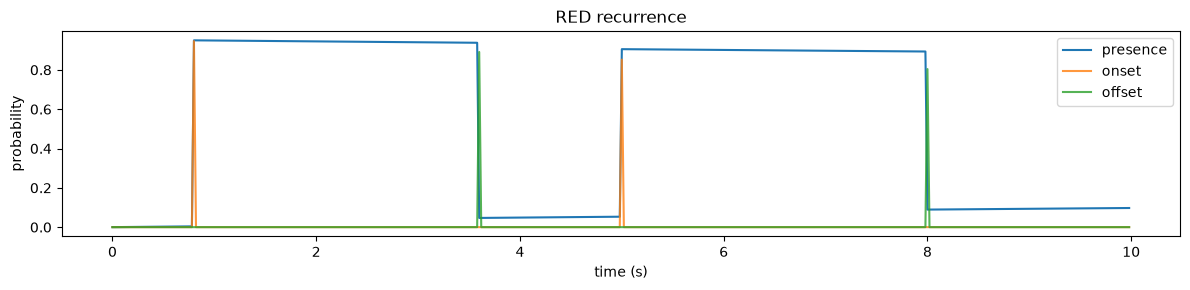

In [11]:
T, C = meta["num_frames"], meta["num_classes"]
p_start = torch.zeros(1, C, T)
p_end = torch.zeros(1, C, T)
clip_dur = T / meta["frame_rate"]
p_start[0, 0, int(0.08 * T)] = 0.95
p_end[0, 0, int(0.36 * T)] = 0.95
p_start[0, 0, int(0.50 * T)] = 0.90
p_end[0, 0, int(0.80 * T)] = 0.90

out_red = epn.RED()(
    torch.logit(p_start.clamp(1e-4, 1 - 1e-4)),
    torch.logit(p_end.clamp(1e-4, 1 - 1e-4)),
)
t = np.arange(T) / meta["frame_rate"]
plt.figure(figsize=(12, 3))
plt.plot(t, out_red["presence"][0, 0], label="presence", lw=1.5)
plt.plot(t, out_red["onset"][0, 0], label="onset", alpha=0.8)
plt.plot(t, out_red["offset"][0, 0], label="offset", alpha=0.8)
plt.xlabel("time (s)"); plt.ylabel("probability"); plt.legend()
plt.title("RED recurrence"); plt.tight_layout(); plt.show()

## 4. Loss terms

In [12]:
criterion = epn.SEDLoss(cfg, lambda_ool=100.0, lambda_iou=2.0)
targets = {k: batch[k].float().to(device) for k in ("pres", "on", "off", "don", "doff")}
with torch.no_grad():
    losses = criterion(outputs, targets)
print({k: float(v) for k, v in losses.items()})

{'loss': 8.64344310760498, 'pres': 0.702618420124054, 'ool': 0.03690780699253082, 'iou': 2.1250219345092773}


## 5. Short training loop

In [13]:
@torch.no_grad()
def evaluate_quick(model, dataset, cfg, method="epn", threshold=0.3, k=15):
    loader = DataLoader(dataset, batch_size=16, shuffle=False, collate_fn=epn.collate)
    preds, gt, pres_all, targ_all = [], [], [], []
    for batch in loader:
        out = model(batch["mel"].float().to(device))
        pres = epn.presence_probability(out).cpu()
        targ = batch["pres"].float().cpu()
        pres_all.append(pres.numpy()); targ_all.append(targ.numpy())
        preds.extend(epn.events_from_model_output(
            out, cfg, method=method, threshold=threshold, filter_len=7, k=k, m=None))
        if dataset.events:
            gt.extend([dataset.events[int(i)] for i in batch["index"].tolist()])
        else:
            gt.extend([epn.frames_to_events(targ[i].numpy().tolist(), cfg.frame_rate,
                                             threshold=0.5)
                       for i in range(targ.shape[0])])
    duration = len(gt) * (cfg.num_frames / cfg.frame_rate)
    frame = epn.frame_metrics(np.concatenate(pres_all), np.concatenate(targ_all))
    return {
        "psds1": epn.psds1(preds, gt, dataset_duration=duration)["psds1"],
        "psds2": epn.psds2(preds, gt, dataset_duration=duration)["psds2"],
        "collar_f1": epn.collar_f1(preds, gt, threshold=threshold)["f1"],
        "frame_f1": frame["f1"],
        "preds": preds,
        "gt": gt,
    }

def train_quick(model, train_ds, val_ds, cfg, epochs=2, batch_size=8, lr=3e-3):
    loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                        collate_fn=epn.collate, drop_last=False)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    criterion = epn.SEDLoss(cfg, lambda_ool=10.0, lambda_iou=1.0)
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        running = []
        for batch in loader:
            mel = batch["mel"].float().to(device)
            targets = {k: batch[k].float().to(device)
                       for k in ("pres", "on", "off", "don", "doff")}
            losses = criterion(model(mel), targets)
            opt.zero_grad()
            losses["loss"].backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            running.append(float(losses["loss"]))
        metrics = evaluate_quick(model, val_ds, cfg)
        metrics["train_loss"] = float(np.mean(running))
        history.append(metrics)
        print(f"epoch {epoch}/{epochs}  train_loss={metrics['train_loss']:.4f}  "
              f"PSDS1={metrics['psds1'] * 100:.2f}  PSDS2={metrics['psds2'] * 100:.2f}  "
              f"collar-F1={metrics['collar_f1'] * 100:.2f}")
    return history

model = epn.build_model(cfg).to(device)
batch_size = 8 if len(train_ds) <= 100 else 32
history = train_quick(model, train_ds, val_ds, cfg, epochs=2, batch_size=batch_size, lr=3e-3)

/var/folders/9p/gk9y0p613xx6vt_bwhgxjshw0000gq/T/ipykernel_6688/252105733.py:47: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:821.)
  running.append(float(losses["loss"]))


epoch 1/2  train_loss=1.8934  PSDS1=2.53  PSDS2=13.24  collar-F1=0.00


epoch 2/2  train_loss=1.5458  PSDS1=3.73  PSDS2=15.27  collar-F1=0.00


## 6. Test evaluation: PSDS1, PSDS2, collar-F1

In [14]:
test_metrics = evaluate_quick(model, test_ds, cfg, threshold=0.3)
for key in ("psds1", "psds2", "collar_f1", "frame_f1"):
    print(f"{key:>10s}: {test_metrics[key]:.4f}")

     psds1: 0.0452
     psds2: 0.1568
 collar_f1: 0.0000
  frame_f1: 0.0000


## 7. EPN vs median filtering on one clip

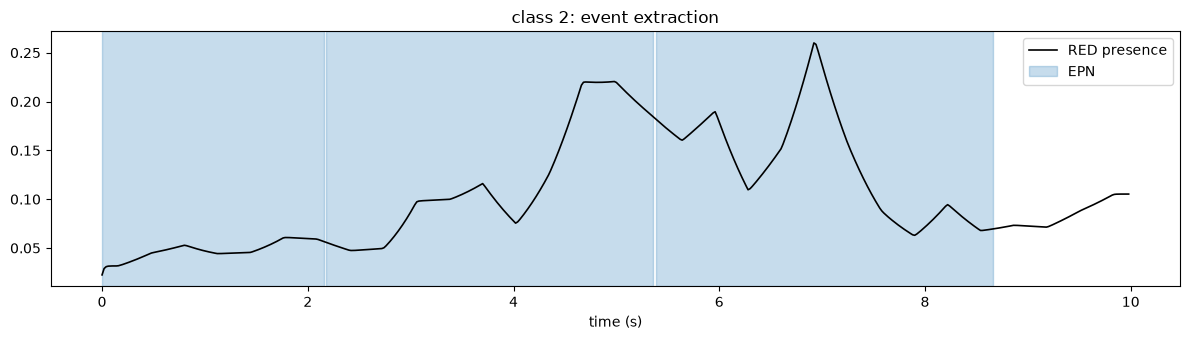

EPN events: 32 | median events: 0


In [15]:
row = test_ds[0]
with torch.no_grad():
    out = model(row["mel"].unsqueeze(0).float().to(device))
pres = epn.presence_probability(out).cpu()
epn_events = epn.epn_inference(
    pres, out["don"].cpu(), out["doff"].cpu(),
    frame_rate=cfg.frame_rate,
    clip_duration=cfg.num_frames / cfg.frame_rate,
    k=15, m=None,
)[0]
mf_events = epn.median_filter_events(
    pres, frame_rate=cfg.frame_rate, threshold=0.3, filter_len=7
)[0]

class_id = int(pres[0].mean(dim=1).argmax())
t = np.arange(cfg.num_frames) / cfg.frame_rate
plt.figure(figsize=(12, 3.5))
plt.plot(t, pres[0, class_id], label="RED presence", color="black", lw=1.2)
for ev in test_ds.ground_truth_events(0):
    if ev.class_id == class_id:
        plt.axvspan(ev.onset, ev.offset, color="tab:green", alpha=0.15, label="ground truth")
for ev in epn_events:
    if ev.class_id == class_id:
        plt.axvspan(ev.onset, ev.offset, color="tab:blue", alpha=0.25, label="EPN")
for ev in mf_events:
    if ev.class_id == class_id:
        plt.axvspan(ev.onset, ev.offset, color="tab:red", alpha=0.15, label="median filter")
handles, labels = plt.gca().get_legend_handles_labels()
unique = dict(zip(labels, handles))
plt.legend(unique.values(), unique.keys())
plt.xlabel("time (s)"); plt.title(f"class {class_id}: event extraction")
plt.tight_layout(); plt.show()
print("EPN events:", len(epn_events), "| median events:", len(mf_events))

## Next steps

- For real results, prepare URBAN-SED and point `DATA_ROOT` at it.
- The repo version adds the full training CLI, checkpointing, W&B and the
  ablation configs; this notebook is the self-contained demonstration.